<H1>Ising</H1> 
A place to fool around with the Ising model
<hr>
<H2>Modification history </H2><br> 
<table>
    <tr>
        <th> Modified </th>
        <th> By </th>
        <th> Reason </th>
    </tr>
    <tr> 
        <td> 19-Nov-26 </td>
        <td> CBL </td> 
        <td> Original </td>
    </tr>
</table>
<hr> 
<H2> References </H2> 
References: <br> 

<H2> Notes </H2>
The 2D ising model Hamiltonian looks like:

$H = -J \sum_{(i,j)} s_i s_j - h \sum_i S_i $

with $s_i = \pm 1$

We can have a matrix of n by n that serves to hold the information for the individual spins. The transistion matrix
for evolving this ends up being quite large. We choose to have a local matrix instead. 

$\Delta E = 2s_{ij}(J \sum_{neighbors} s_{kl} + h)

Then using the metropolis algorithm we accept the flip with probability 

$ P_{accept} = min(1,e^{-{{{\Delta E}}\over(k_B T)}})$

Proceedure for Metropolis algorithm: 
<ol>
    <li> Choose the lattice site (i,j) at random </li>
    <li> Calculate the energy change $\Delta E$ if its spin were flipped </li>
    <li> If $\Delta E \leq 0$, accept the flip</li>
    <li> If $\Delta E \gt 0$, accept it with probablity $e^{-{{{\Delta E}}\over(k_B T)}}$ </li>
    <li> Repeat</li>
</ol>

This algorighm generates configurations sampled from the Boltzman distribution: 

$P(S) \propto e^{-{{H(S)}\over{k_B T}}}$

we can use the sensor to modify the local field $h_{ij}$ later. 

<ul>
    <li> Start with at 32 x 32 lattice for simulation</li>
    <li> Start with random configuration and watch the domains emerge</li>
    <li> Later start with ordered lattice and watch disorder arise</li>
    <li> add in local perterbations</li>
</ul>

As a benchmark test, ${{k_B T_c}\over J} \approx 2.269$ Below this value large ordered domains become favorable. 

In [1]:
# My imports
import numpy as np
import matplotlib.pyplot as plt
import time
import math
import scipy.constants   as konst

Text(0.5, 1.0, 'Initial random configuration')

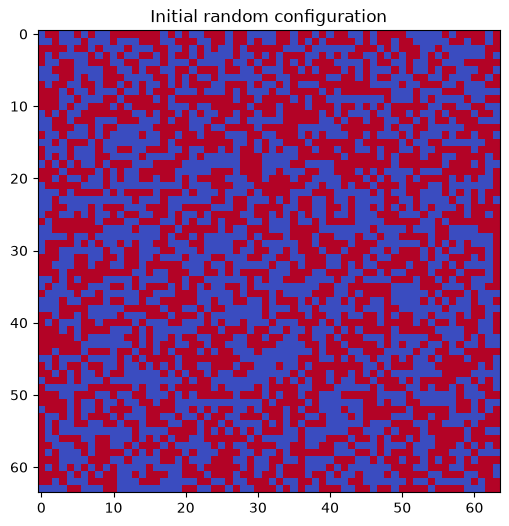

In [30]:
# Initialize

N = 64       # lattice size
J = 1.0      # Spin-Spin coupling strength
T = 1.5      # Temperature in k
h = 0.0      # Magnetic field, or coupling energy in Joules = -uBs_i

rng = np.random.default_rng(42)

# Random initial spins of: +1 or -1
spins = rng.choice([-1,1], size=(N,N))

plt.figure(figsize=(6,6))
plt.imshow(spins, cmap="coolwarm", vmin=-1, interpolation="nearest")
plt.title("Initial random configuration")

# if in python alone, we need a plt.show()

In [26]:
def energy_per_spin(spins, J=1.0, h=0.0):
    neighbors = (
        np.roll(spins, -1, axis=0)
        + np.roll(spins, -1, axis=1)
    )
    E = -J * np.sum(spins*neighbors)
    E -= h * np.sum(spins)
    return E/spins.size

In [11]:
"""
metropolis sweep
Each sweep attempts N^2 spin flips. The four nearest neighbors determine the energy change. 
"""
def metropolis_sweep( spins, T, J=1.0, h=0.0):
    N, M = spins.shape
    for _ in range(N * M):
        i = rng.integers(N)
        j = rng.integers(M)

        # periodic boundry conditions
        neighbors = (
        spins[(i + 1) % N, j] 
            + spins[(i-1)%N, j]
            + spins[i, (j+1)%M]
            + spins[i, (j-1)%M]
        )

        dE = 2 * spins[i,j] * (J * neighbors + h)
        if dE < 0 or rng.random() < np.exp(-dE/T) :
            spins[i,j] *= -1

    return spins

Magnetization: -0.0059
Energy per spin: -0.0176
Magnetization: 0.1895
Energy per spin: -1.7881
Magnetization: 0.2495
Energy per spin: -1.8516
Magnetization: 0.4668
Energy per spin: -1.8584
Magnetization: -0.4326
Energy per spin: -1.8584


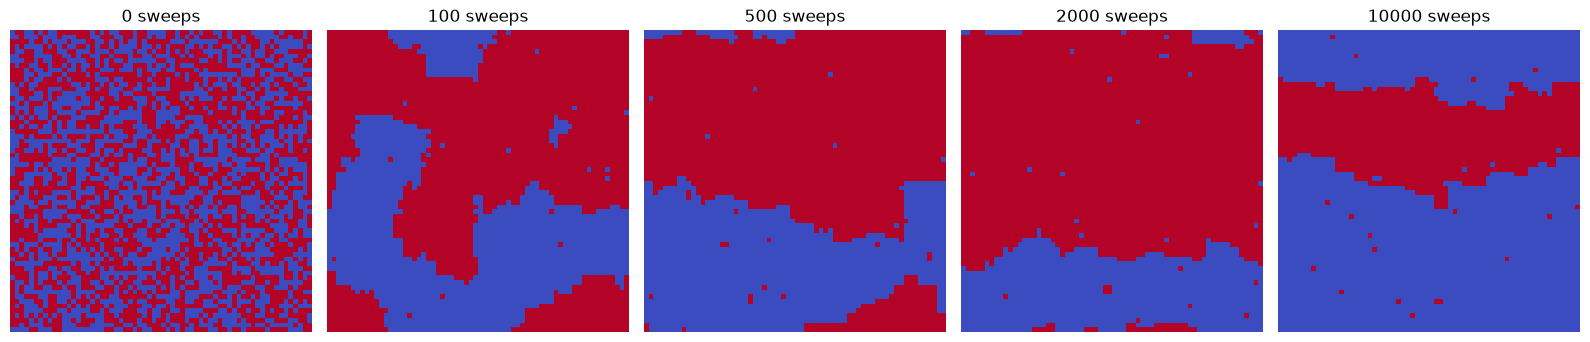

In [31]:
# Now evolve the system 
# Observe after 0, 10 50 200 1000 iterations

#checkpoints = [0, 10, 50, 200, 1000]
checkpoints = [0, 100, 500, 2000, 10000]

fig, axes = plt.subplots(1, len(checkpoints),figsize=(16,4))

completed = 0

for ax, target in zip(axes, checkpoints):
    for _ in range(target-completed):
         metropolis_sweep( spins, T,J,h)
    completed = target

    ax.imshow( spins, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(f"{target} sweeps")
    ax.axis("off")

    # per checkpoint
    energy = energy_per_spin(spins, J, h)
    print(f"Magnetization: {np.mean(spins):.4f}")
    print(f"Energy per spin: {energy:.4f}")
    
plt.tight_layout()
#plt.show()
                 

<H1> Measure the magnetization</H1>
Quantative check that the average magnetization per spin is:

$m = {1\over {N^2}}\sum_{i,j} s_{ij}$

In [24]:
magnetization = np.mean(spins)
print(f"Magnetization: {magnetization: .4f}")

Magnetization: -0.4326


The T used in the above cells is really a scaled dimensionaless value. 

$T^* = {{k_B * T_{physical}}\over{J}}$ 

Lets invert that:

In [21]:
# J is not in joules, assume that the coupling is about 1meV
T_physical = J*1.0e-3 * konst.eV *T/konst.k
print(f"Actual temperature: {T_physical:.2f} K")

Actual temperature: 17.41 K


In [28]:
energy = energy_per_spin(spins, J, h)
print(f"Magnetization: {np.mean(spins):.4f}")
print(f"Energy per spin: {energy:.4f}")

Magnetization: -0.4326
Energy per spin: -1.8584
